# Clasificación de diabetes a partir de indicadores clínicos y demográficos
**Minería de Datos — Actividad 1, tercer corte (versión final)**

**Integrantes:** José Rivas, Sebastián Muñoz y Camilo Camargo  
**Tipo de problema:** clasificación supervisada.  
**Variable objetivo:** `Outcome` (0 = clase negativa, 1 = clase positiva).  
**Pregunta del proyecto:** ¿Qué tan bien pueden la regresión logística y un árbol de decisión clasificar `Outcome` a partir de ocho indicadores clínicos y demográficos?

Este notebook retoma el flujo del segundo corte para revisar la calidad de los datos, comparar los dos modelos, comprobar el desempeño con validación cruzada, guardar el pipeline completo y verificar que el modelo serializado dé la misma predicción. Está ejecutado de principio a fin: todas las cifras que se comentan en los textos salen de las salidas que se ven en cada sección.

**Resumen de resultados (detalle en la sección 13):**
- El conjunto tiene 768 registros y 8 variables predictoras; el 34.9 % son casos de clase 1.
- Modelo seleccionado: **árbol de decisión**, por tener el mayor recall de la clase 1 en validación cruzada. En el conjunto de prueba obtuvo recall 0.852, precision 0.561, F1 0.676 y accuracy 0.714.
- La regresión logística fue más estable y tuvo mejor AUC, accuracy, precision y F1 en validación cruzada. Cuál conviene usar depende de qué error se quiera evitar más.
- La glucosa es la variable que más pesa en ambos modelos, seguida del BMI.

**Aviso:** este es un ejercicio académico. El conjunto de datos no representa a toda la población y el modelo no diagnostica ni sustituye la valoración de profesionales de la salud.

## 0. Preparación del entorno y configuración

El notebook intenta leer `diabetes.csv` desde la misma carpeta. Si no lo encuentra, intenta descargar la versión pública del conjunto Pima Indians Diabetes. Si la descarga no está disponible, hay que colocar el CSV del proyecto en la carpeta del notebook con el nombre `diabetes.csv` y volver a ejecutar esta celda.

La fuente de referencia del proyecto continúa siendo el conjunto indicado en el segundo informe de avance: [Kaggle — Diabetes Dataset](https://www.kaggle.com/datasets/amineipad/diabetes-dataset). Para facilitar la reproducción también se deja un espejo público con el formato estándar Pima.

La última línea de la salida muestra las versiones de las librerías con las que se ejecutó el notebook. Conviene usarlas en el `requirements.txt` de la aplicación, porque un archivo `.joblib` guardado con una versión de scikit-learn puede dar problemas al cargarse con otra.

In [4]:
from pathlib import Path
import json
import warnings
import urllib.request

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
DATA_FILE = Path("diabetes.csv")
MODEL_FILE = Path("pipeline_diabetes.joblib")
METRICS_FILE = Path("metricas_modelo.json")
KNOWN_CASE_FILE = Path("caso_prueba_conocido.json")

DATA_URL = (
    "https://raw.githubusercontent.com/npradaschnor/"
    "Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
)

FEATURES = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"
]
TARGET = "Outcome"
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

import sys, sklearn
print("Entorno preparado.")
print("Carpeta de trabajo:", Path.cwd())
print("Versiones -> Python:", sys.version.split()[0], "| pandas:", pd.__version__,
      "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__, "| joblib:", joblib.__version__)

Matplotlib is building the font cache; this may take a moment.


Entorno preparado.
Carpeta de trabajo: c:\Users\camil\Downloads
Versiones -> Python: 3.14.7 | pandas: 3.1.1 | numpy: 2.5.5 | scikit-learn: 1.9.1 | joblib: 1.6.0


## 1. Carga y validación inicial del conjunto de datos

Se comprueba que existan las ocho variables predictoras y la variable objetivo. También se validan los tipos de datos y que `Outcome` contenga únicamente las clases 0 y 1. No se generan registros artificiales: los resultados se calculan con el CSV real que se cargue.

In [5]:
def load_dataset():
    if DATA_FILE.exists():
        data = pd.read_csv(DATA_FILE)
        print(f"Archivo local cargado: {DATA_FILE.resolve()}")
    else:
        try:
            with urllib.request.urlopen(DATA_URL, timeout=20) as response:
                from io import BytesIO
                data = pd.read_csv(BytesIO(response.read()))
            print("Dataset descargado desde el espejo público.")
        except Exception as exc:
            raise FileNotFoundError(
                "No fue posible encontrar ni descargar diabetes.csv. "
                "Coloca el CSV real del proyecto en la misma carpeta con ese nombre "
                "y vuelve a ejecutar. No se han creado datos ficticios."
            ) from exc

    missing_columns = [c for c in FEATURES + [TARGET] if c not in data.columns]
    if missing_columns:
        raise ValueError(
            f"El CSV no contiene las columnas esperadas: {missing_columns}. "
            "Verifica que corresponda al dataset Pima Indians del proyecto."
        )

    data = data[FEATURES + [TARGET]].copy()
    for column in FEATURES + [TARGET]:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    data = data.dropna(subset=[TARGET])
    if not set(data[TARGET].unique()).issubset({0, 1}):
        raise ValueError("La columna Outcome debe contener únicamente 0 y 1.")

    data[TARGET] = data[TARGET].astype(int)
    if data.empty:
        raise ValueError("El conjunto de datos está vacío después de la validación.")
    return data

df = load_dataset()

print("Dimensiones (filas, columnas):", df.shape)
print("\nPrimeros registros:")
display(df.head())
print("\nTipos de datos:")
display(df.dtypes.to_frame("Tipo"))
print("\nResumen estadístico:")
display(df.describe().T)
print("\nValores faltantes por columna:")
display(df.isna().sum().to_frame("Valores faltantes"))
print("\nFilas duplicadas:", int(df.duplicated().sum()))
print("\nDistribución de Outcome:")
display(df[TARGET].value_counts().sort_index().to_frame("Cantidad"))
print("\nProporción de Outcome:")
display((df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2).to_frame("Porcentaje"))

Dataset descargado desde el espejo público.
Dimensiones (filas, columnas): (768, 9)

Primeros registros:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Tipos de datos:


,Tipo
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64



Resumen estadístico:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


... (2 outputs left out)


Filas duplicadas: 0

Distribución de Outcome:


,Cantidad
Outcome,
0,500
1,268



Proporción de Outcome:


,Porcentaje
Outcome,
0,65.1
1,34.9


**Lectura de la carga de datos.** El archivo tiene 768 registros y 9 columnas (8 predictoras y `Outcome`). No hay valores nulos ni filas duplicadas, y todas las columnas son numéricas. `Outcome` tiene 500 registros en la clase 0 y 268 en la clase 1 (34.9 %). Los nulos que aparecen más adelante no vienen del archivo, sino de convertir los ceros no plausibles en valores faltantes (sección 3).

## 2. Análisis exploratorio de datos (EDA)

Se revisa la distribución de la variable objetivo, la glucosa por clase, la correlación entre variables y los ceros observados en mediciones donde un cero puede representar un dato no registrado. Estas gráficas describen el conjunto, pero no demuestran causalidad.

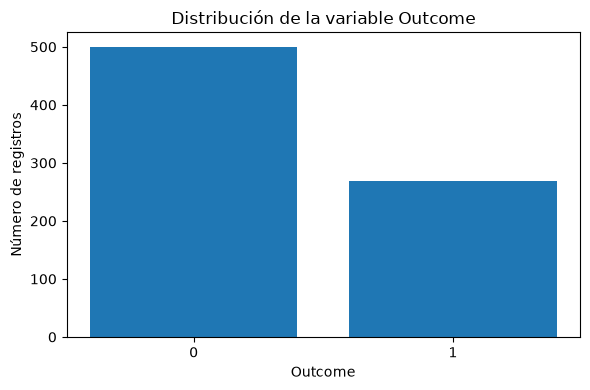

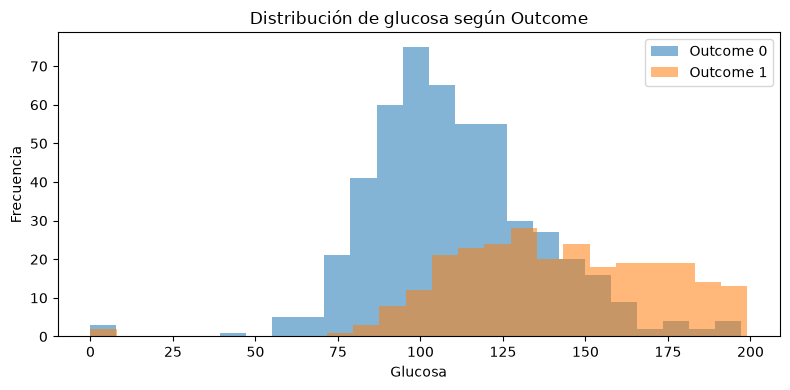

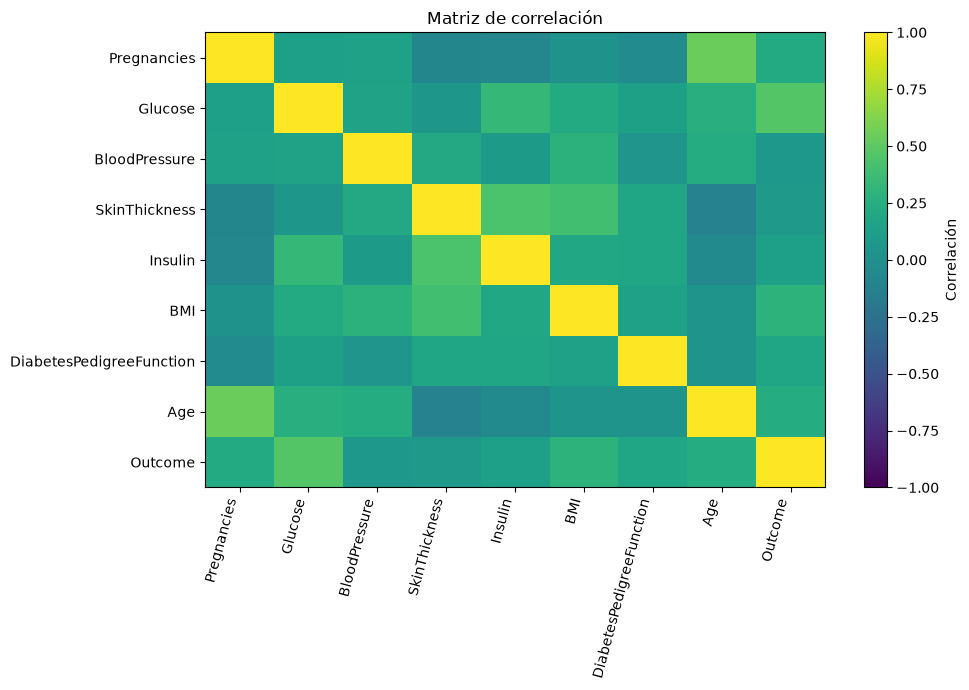

,Ceros observados
Insulin,374
SkinThickness,227
BloodPressure,35
BMI,11
Glucose,5


Glucosa por clase:


,mean,median
Outcome,,
0,109.98,107.0
1,141.26,140.0



Correlación de cada variable con Outcome:


,Correlación con Outcome
Glucose,0.467
BMI,0.293
Age,0.238
Pregnancies,0.222
DiabetesPedigreeFunction,0.174
Insulin,0.131
SkinThickness,0.075
BloodPressure,0.065



Ceros en Pregnancies (aquí el cero sí es un valor válido): 111

Porcentaje de ceros en las columnas donde un cero no es plausible:


,% de ceros
Insulin,48.7
SkinThickness,29.6
BloodPressure,4.6
BMI,1.4
Glucose,0.7


In [6]:
# Distribución de la variable objetivo
counts = df[TARGET].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Distribución de la variable Outcome")
plt.xlabel("Outcome")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

# Distribución de glucosa separada por clase
plt.figure(figsize=(8, 4))
for outcome in sorted(df[TARGET].unique()):
    values = df.loc[df[TARGET] == outcome, "Glucose"].dropna()
    plt.hist(values, bins=25, alpha=0.55, label=f"Outcome {outcome}")
plt.title("Distribución de glucosa según Outcome")
plt.xlabel("Glucosa")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

# Matriz de correlación
corr = df[FEATURES + [TARGET]].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Matriz de correlación")
fig.colorbar(im, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()

# Posibles valores no registrados codificados como cero
zero_counts = (df[ZERO_AS_MISSING] == 0).sum().sort_values(ascending=False)
display(zero_counts.to_frame("Ceros observados"))

# Cifras de apoyo para la lectura del EDA
print("Glucosa por clase:")
display(df.groupby(TARGET)["Glucose"].agg(["mean", "median"]).round(2))
print("\nCorrelación de cada variable con Outcome:")
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("Correlación con Outcome"))
print("\nCeros en Pregnancies (aquí el cero sí es un valor válido):", int((df["Pregnancies"] == 0).sum()))
print("\nPorcentaje de ceros en las columnas donde un cero no es plausible:")
display(((df[ZERO_AS_MISSING] == 0).mean() * 100).round(1).sort_values(ascending=False).to_frame("% de ceros"))

**Lectura del EDA.**

- **Variable objetivo.** Hay un desbalance moderado: 500 casos de clase 0 contra 268 de clase 1. Un modelo que respondiera siempre 0 acertaría el 65.1 % de las veces, por eso la accuracy sola no sirve para juzgar y se revisan también precision, recall y F1 de la clase 1.
- **Glucosa.** La glucosa promedio es 141.26 en la clase 1 y 109.98 en la clase 0 (medianas de 140 y 107). En el histograma la clase 1 aparece desplazada hacia valores más altos.
- **Correlaciones con `Outcome`.** Glucose es la más alta (0.467), seguida de BMI (0.293), Age (0.238) y Pregnancies (0.222). DiabetesPedigreeFunction tiene 0.174, Insulin 0.131, y SkinThickness (0.075) y BloodPressure (0.065) casi no se relacionan de forma lineal con la clase.
- **Ceros.** Insulin tiene 374 ceros (48.7 %), SkinThickness 227 (29.6 %), BloodPressure 35 (4.6 %), BMI 11 (1.4 %) y Glucose 5 (0.7 %). Una presión arterial, un BMI o una glucosa de cero no son valores posibles en una persona viva, así que se interpretan como mediciones no registradas. En `Pregnancies` los 111 ceros sí son válidos (ninguna gestación), por eso esa columna no se toca.
- **Alcance.** Estas relaciones son asociaciones dentro de este conjunto; no indican que una variable cause la diabetes.

## 3. Preparación de los datos y control de calidad

En `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI`, los ceros se tratan como posibles mediciones no registradas, siguiendo el criterio metodológico del segundo avance. La imputación por mediana se incorpora dentro de cada pipeline; de esta manera, la mediana se aprende solamente con los datos usados para entrenar cada partición y se reduce el riesgo de fuga de información.

Se conserva `Outcome` como objetivo y las ocho variables originales como predictoras.

In [7]:
def prepare_features(X):
    X = X.copy()
    for column in ZERO_AS_MISSING:
        X[column] = X[column].replace(0, np.nan)
    return X

X = prepare_features(df[FEATURES])
y = df[TARGET].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("\nValores faltantes después de revisar ceros:")
display(X.isna().sum().to_frame("Faltantes"))
print("\nBalance de clases:")
display(y.value_counts().sort_index().to_frame("Cantidad"))

# División estratificada: conserva aproximadamente la proporción de las clases.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("Proporción de clase positiva en entrenamiento:", round(y_train.mean(), 3))
print("Proporción de clase positiva en prueba:", round(y_test.mean(), 3))

Dimensiones de X: (768, 8)
Dimensiones de y: (768,)

Valores faltantes después de revisar ceros:


,Faltantes
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0



Balance de clases:


,Cantidad
Outcome,
0,500
1,268


Registros de entrenamiento: 614
Registros de prueba: 154
Proporción de clase positiva en entrenamiento: 0.349
Proporción de clase positiva en prueba: 0.351


**Lectura de la preparación.** Después de convertir los ceros en faltantes quedan 5 en Glucose, 35 en BloodPressure, 227 en SkinThickness, 374 en Insulin y 11 en BMI, que coinciden con los conteos del EDA. La división 80/20 deja 614 registros para entrenar y 154 para probar, y la proporción de clase 1 se mantiene casi igual en ambas partes (0.349 en entrenamiento y 0.351 en prueba), de modo que la estratificación funcionó. El conjunto de prueba tiene 54 casos positivos; es un tamaño pequeño y hay que tenerlo presente al interpretar las diferencias entre modelos.

## 4. Construcción de los modelos

Se comparan los dos algoritmos conservados del proyecto: regresión logística y árbol de decisión. Ambos pipelines incluyen imputación por mediana. La regresión logística también incorpora escalamiento, mientras que el árbol de decisión no requiere esa transformación.

Los dos modelos usan `class_weight="balanced"` para que la clase 1, que es la minoritaria, pese más durante el entrenamiento. En el árbol se fijaron `max_depth=4` y `min_samples_leaf=8` para limitar su tamaño y reducir el sobreajuste. Estos valores se definieron de entrada y no se ajustaron con una búsqueda de hiperparámetros; queda como posible mejora.

In [8]:
def build_models():
    logistic_preprocessing = ColumnTransformer(
        transformers=[
            ("numeric", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), FEATURES)
        ],
        remainder="drop"
    )

    tree_preprocessing = ColumnTransformer(
        transformers=[
            ("numeric", SimpleImputer(strategy="median"), FEATURES)
        ],
        remainder="drop"
    )

    logistic_pipeline = Pipeline(steps=[
        ("preprocessing", logistic_preprocessing),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

    tree_pipeline = Pipeline(steps=[
        ("preprocessing", tree_preprocessing),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=8,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])

    return {
        "Regresión logística": logistic_pipeline,
        "Árbol de decisión": tree_pipeline
    }

models = build_models()
print("Modelos construidos:", ", ".join(models.keys()))

Modelos construidos: Regresión logística, Árbol de decisión


## 5. Entrenamiento y validación cruzada

La evaluación utiliza una partición de entrenamiento y prueba estratificada y validación cruzada estratificada de cinco particiones sobre los datos de entrenamiento. Se reportan accuracy, precision, recall, F1 y AUC; precision, recall y F1 se calculan para la clase positiva.

Se muestran dos tablas: una con el desempeño en el conjunto de prueba y otra con el promedio y la desviación estándar en validación cruzada. La selección del modelo (sección 8) se hace con la validación cruzada, sin usar el conjunto de prueba, y no se basa únicamente en accuracy: se prioriza el recall de la clase positiva.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

fitted_models = {}
evaluation = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)
    test_proba = pipeline.predict_proba(X_test)[:, 1]

    cv_result = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, return_train_score=False
    )

    evaluation[name] = {
        "accuracy": float(accuracy_score(y_test, test_pred)),
        "precision_1": float(precision_score(y_test, test_pred, zero_division=0)),
        "recall_1": float(recall_score(y_test, test_pred, zero_division=0)),
        "f1_1": float(f1_score(y_test, test_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, test_proba)),
        "train_accuracy": float(accuracy_score(y_train, train_pred)),
        "cv_accuracy_mean": float(np.mean(cv_result["test_accuracy"])),
        "cv_precision_mean": float(np.mean(cv_result["test_precision"])),
        "cv_recall_mean": float(np.mean(cv_result["test_recall"])),
        "cv_recall_std": float(np.std(cv_result["test_recall"], ddof=1)),
        "cv_f1_mean": float(np.mean(cv_result["test_f1"])),
        "cv_f1_std": float(np.std(cv_result["test_f1"], ddof=1)),
        "cv_roc_auc_mean": float(np.mean(cv_result["test_roc_auc"])),
        "confusion_matrix": confusion_matrix(y_test, test_pred, labels=[0, 1]).tolist(),
        "classification_report": classification_report(
            y_test, test_pred, labels=[0, 1],
            output_dict=True, zero_division=0
        )
    }
    fitted_models[name] = pipeline

eval_df = pd.DataFrame(evaluation).T

print("Resultados en el conjunto de prueba (154 registros):")
test_table = eval_df[["accuracy", "precision_1", "recall_1", "f1_1", "roc_auc", "train_accuracy"]].astype(float)
test_table.columns = ["Accuracy", "Precision (1)", "Recall (1)", "F1 (1)", "AUC", "Accuracy entrenamiento"]
display(test_table.round(4))

print("\nResultados en validación cruzada de 5 particiones (solo datos de entrenamiento):")
cv_table = eval_df[["cv_accuracy_mean", "cv_precision_mean", "cv_recall_mean", "cv_recall_std",
                    "cv_f1_mean", "cv_f1_std", "cv_roc_auc_mean"]].astype(float)
cv_table.columns = ["Accuracy", "Precision (1)", "Recall (1)", "Desv. recall", "F1 (1)", "Desv. F1", "AUC"]
display(cv_table.round(4))

Resultados en el conjunto de prueba (154 registros):


,Accuracy,Precision (1),Recall (1),F1 (1),AUC,Accuracy entrenamiento
Regresión logística,0.7338,0.6032,0.7037,0.6496,0.8126,0.7590
Árbol de decisión,0.7143,0.5610,0.8519,0.6765,0.7937,0.7622



Resultados en validación cruzada de 5 particiones (solo datos de entrenamiento):


,Accuracy,Precision (1),Recall (1),Desv. recall,F1 (1),Desv. F1,AUC
Regresión logística,0.7622,0.6486,0.7010,0.0441,0.6724,0.0149,0.8444
Árbol de decisión,0.6970,0.5534,0.7386,0.1076,0.6285,0.0537,0.7855


**Lectura de las tablas.**

- **En el conjunto de prueba**, el árbol tiene mayor recall (0.852 contra 0.704) y mayor F1 (0.676 contra 0.650); la regresión logística tiene mayor accuracy (0.734 contra 0.714), mayor precision (0.603 contra 0.561) y mayor AUC (0.813 contra 0.794).
- **En validación cruzada**, la regresión logística es mejor en accuracy (0.762 contra 0.697), precision (0.649 contra 0.553), F1 (0.672 contra 0.628) y AUC (0.844 contra 0.786). El árbol solo gana en recall (0.739 contra 0.701).
- **Estabilidad.** El recall del árbol varía bastante entre particiones (desviación de 0.108, contra 0.044 de la logística) y su F1 también (0.054 contra 0.015). La ventaja del árbol en recall de validación cruzada es de unos 3.8 puntos, menor que su propia variación entre particiones, así que por sí sola no es una diferencia concluyente.
- **Sobreajuste.** La diferencia entre accuracy de entrenamiento y de prueba es 0.048 en el árbol (0.762 contra 0.714) y 0.025 en la regresión logística (0.759 contra 0.734). Es pequeña en ambos casos; no se observa un sobreajuste fuerte.

## 6. Comparación de errores y matrices de confusión

La matriz de confusión permite distinguir verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos. En este problema se debe prestar especial atención a los falsos negativos y al recall de la clase 1.


Regresión logística
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



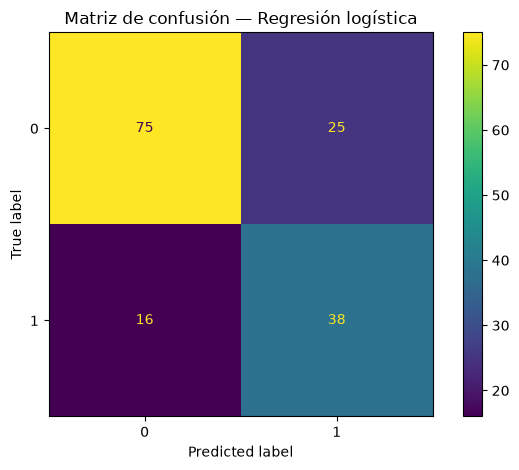

TN=75 | FP=25 | FN=16 | TP=38

Árbol de decisión
              precision    recall  f1-score   support

           0       0.89      0.64      0.74       100
           1       0.56      0.85      0.68        54

    accuracy                           0.71       154
   macro avg       0.72      0.75      0.71       154
weighted avg       0.77      0.71      0.72       154



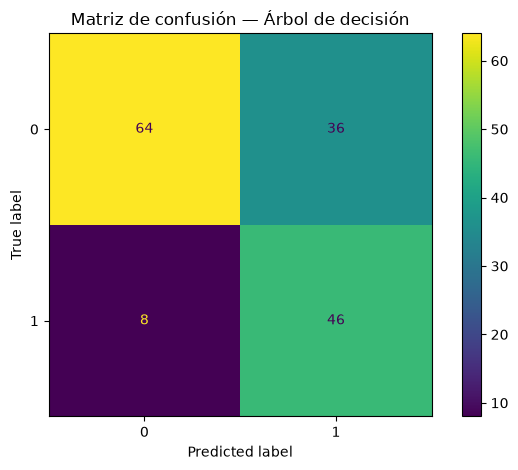

TN=64 | FP=36 | FN=8 | TP=46


In [10]:
for name, pipeline in fitted_models.items():
    predictions = pipeline.predict(X_test)
    print("\n", "=" * 60)
    print(name)
    print(classification_report(y_test, predictions, labels=[0, 1], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1], values_format="d"
    )
    plt.title(f"Matriz de confusión — {name}")
    plt.tight_layout()
    plt.show()

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()
    print(f"TN={tn} | FP={fp} | FN={fn} | TP={tp}")

**Lectura de las matrices de confusión (154 registros de prueba: 100 de clase 0 y 54 de clase 1).**

| Modelo | VN | FP | FN | VP | Positivos no detectados | Negativos clasificados como positivos |
|---|---|---|---|---|---|---|
| Regresión logística | 75 | 25 | 16 | 38 | 16 de 54 (29.6 %) | 25 de 100 (25 %) |
| Árbol de decisión | 64 | 36 | 8 | 46 | 8 de 54 (14.8 %) | 36 de 100 (36 %) |

El árbol detecta 8 casos positivos más que la regresión logística (46 contra 38), pero a cambio genera 11 falsos positivos adicionales (36 contra 25). Es un intercambio entre los dos tipos de error: el árbol es más sensible y menos específico. En un contexto de tamizaje, dejar pasar a una persona con diabetes suele considerarse más grave que enviar a una prueba de confirmación a alguien que no la tiene, y por eso en este proyecto se prioriza el recall. Aun así, con 54 casos positivos, un solo caso cambia el recall en unos 1.9 puntos, y estas cifras son de una sola partición.

## 7. Curva ROC, variables más influyentes y estructura del árbol

Hasta aquí los modelos se compararon con un punto de corte fijo (0.5 de probabilidad). La curva ROC y el AUC permiten compararlos sin depender de ese corte. Además, los coeficientes de la regresión logística y la importancia de variables del árbol ayudan a entender qué está usando cada modelo para decidir.

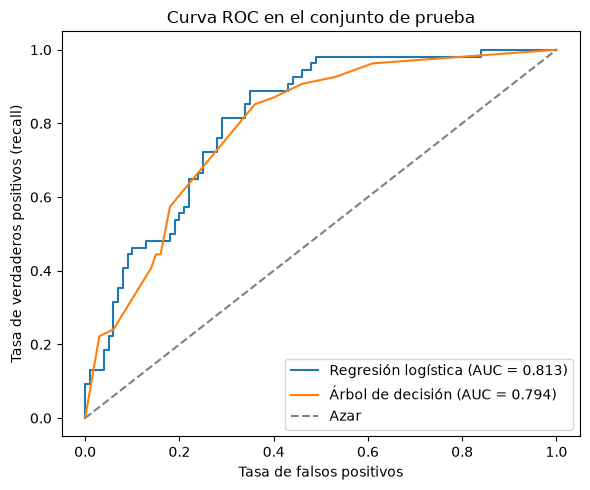

Coeficientes de la regresión logística (variables estandarizadas):


,Coeficiente,Razón de momios (por 1 desv. est.)
Glucose,1.183,3.266
BMI,0.710,2.033
Pregnancies,0.373,1.452
DiabetesPedigreeFunction,0.288,1.333
Age,0.186,1.205
SkinThickness,0.014,1.014
BloodPressure,-0.015,0.985
Insulin,-0.045,0.956


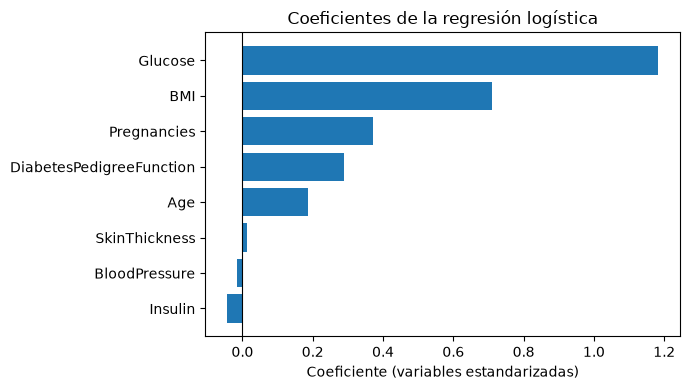


Importancia de variables en el árbol de decisión:


,Importancia
Glucose,0.538
BMI,0.199
Age,0.127
Insulin,0.080
Pregnancies,0.025
SkinThickness,0.016
DiabetesPedigreeFunction,0.015
BloodPressure,0.000


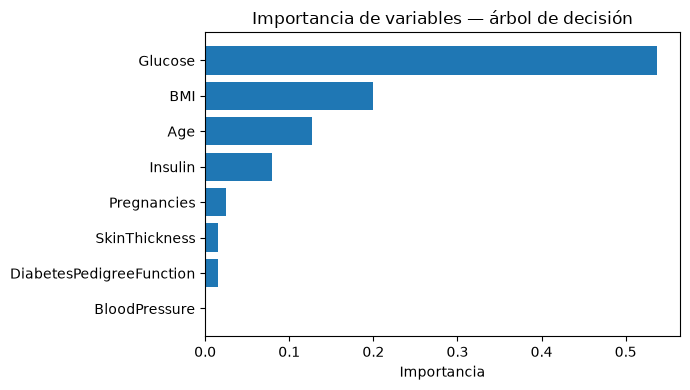

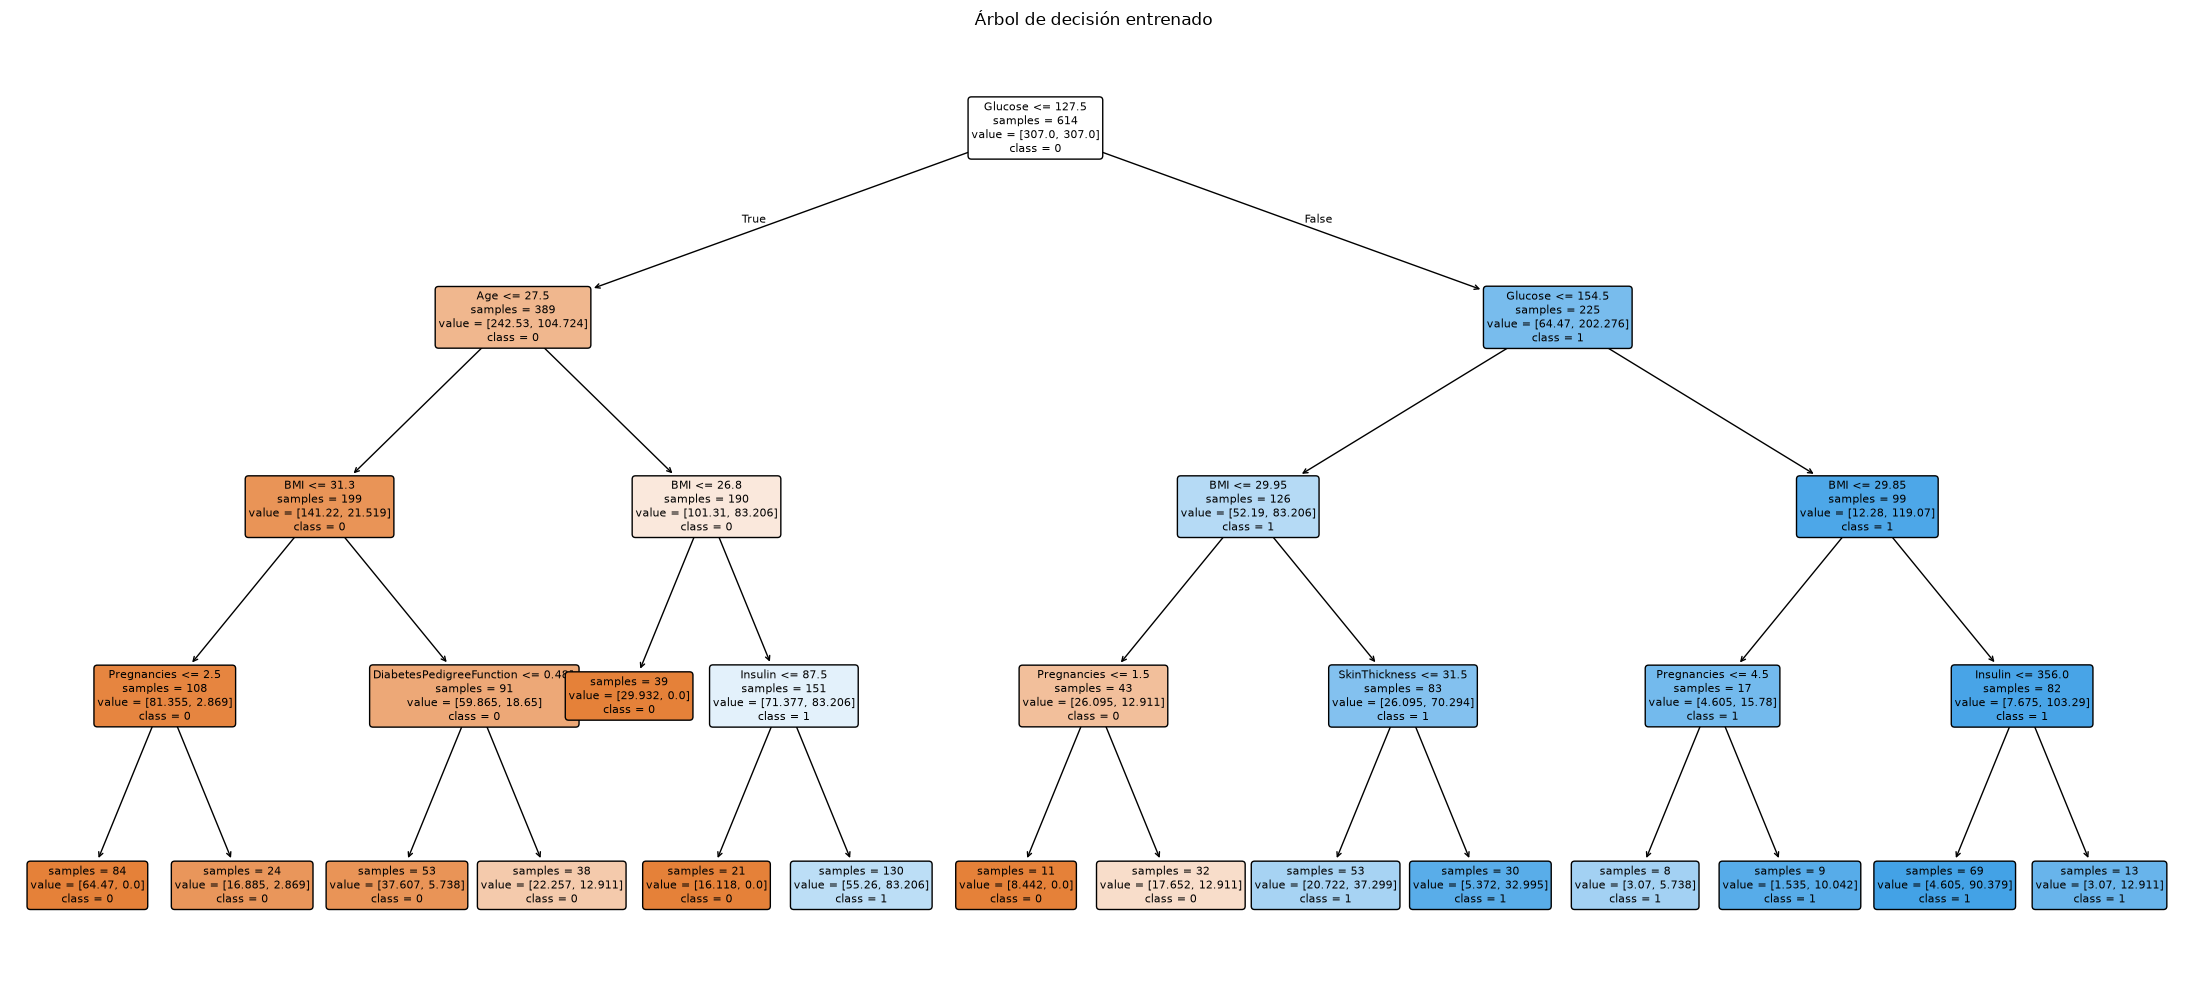

In [11]:
# Curva ROC de ambos modelos en el conjunto de prueba
plt.figure(figsize=(6, 5))
for name, pipeline in fitted_models.items():
    proba = pipeline.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curva ROC en el conjunto de prueba")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Regresión logística: coeficientes sobre variables estandarizadas
logit = fitted_models["Regresión logística"].named_steps["model"]
coef_table = pd.DataFrame({
    "Coeficiente": logit.coef_[0],
    "Razón de momios (por 1 desv. est.)": np.exp(logit.coef_[0])
}, index=FEATURES).sort_values("Coeficiente", ascending=False)
print("Coeficientes de la regresión logística (variables estandarizadas):")
display(coef_table.round(3))

plt.figure(figsize=(7, 4))
plt.barh(coef_table.index[::-1], coef_table["Coeficiente"][::-1])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coeficientes de la regresión logística")
plt.xlabel("Coeficiente (variables estandarizadas)")
plt.tight_layout()
plt.show()

# Árbol de decisión: importancia de las variables
tree_model = fitted_models["Árbol de decisión"].named_steps["model"]
importance_table = pd.Series(tree_model.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("\nImportancia de variables en el árbol de decisión:")
display(importance_table.round(3).to_frame("Importancia"))

plt.figure(figsize=(7, 4))
plt.barh(importance_table.index[::-1], importance_table.values[::-1])
plt.title("Importancia de variables — árbol de decisión")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

# Estructura del árbol (profundidad máxima 4)
plt.figure(figsize=(22, 10))
plot_tree(tree_model, feature_names=FEATURES, class_names=["0", "1"],
          filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Árbol de decisión entrenado")
plt.tight_layout()
plt.show()

**Lectura de la curva ROC, las variables y el árbol.**

- **ROC y AUC.** La regresión logística tiene mayor AUC que el árbol tanto en prueba (0.813 contra 0.794) como en validación cruzada (0.844 contra 0.786). Esto sugiere que la regresión logística separa mejor las dos clases en general, y que la ventaja del árbol en recall viene más de trabajar en un punto de operación más sensible (con más falsos positivos) que de una mejor separación.
- **Regresión logística.** Con las variables estandarizadas, los coeficientes más altos son Glucose (1.183, razón de momios de 3.27 por cada desviación estándar), BMI (0.710, razón de 2.03), Pregnancies (0.373), DiabetesPedigreeFunction (0.288) y Age (0.186). SkinThickness (0.014), BloodPressure (-0.015) e Insulin (-0.045) están prácticamente en cero.
- **Árbol de decisión.** La importancia se concentra en Glucose (0.538), BMI (0.199) y Age (0.127); Insulin aporta 0.080 y BloodPressure 0.000. La primera división del árbol es `Glucose <= 127.5`; a la derecha se vuelve a dividir por glucosa (`<= 154.5`) y a la izquierda por edad (`<= 27.5`). Los valores `value` de cada nodo están ponderados por `class_weight`, por eso la raíz muestra [307, 307] aunque el entrenamiento tiene 614 registros desiguales por clase.
- **Coincidencia entre modelos.** Ambos modelos dan el mayor peso a la glucosa y después al BMI, y coincide con lo visto en el EDA. Insulin aparece con algo de importancia en el árbol pero casi nula en la regresión logística; como casi la mitad de sus valores se imputaron, es mejor no sacar conclusiones sobre esa variable.
- Todo esto describe cómo usan los datos los modelos; no demuestra relaciones causales.

## 8. Selección del modelo y revisión de sobreajuste

Se elige el modelo con mayor recall de la clase positiva **en validación cruzada**. Si hay empate, se comparan F1 y precision, también de validación cruzada. Así el conjunto de prueba no interviene en la decisión y se conserva como evaluación final del modelo elegido. También se observa la diferencia entre accuracy de entrenamiento y prueba como una señal descriptiva de posible sobreajuste; esta diferencia no debe interpretarse de forma aislada.

In [12]:
# Regla de selección: mayor recall de la clase 1 en validación cruzada (solo entrenamiento);
# desempate por F1 y luego por precision, también de validación cruzada.
# El conjunto de prueba no interviene en la elección: queda como evaluación final.
selected_name = max(
    evaluation,
    key=lambda name: (
        evaluation[name]["cv_recall_mean"],
        evaluation[name]["cv_f1_mean"],
        evaluation[name]["cv_precision_mean"]
    )
)
selected_pipeline = fitted_models[selected_name]
selected_result = evaluation[selected_name]

print("Modelo seleccionado:", selected_name)
print("Criterio: recall de clase 1 en validación cruzada; desempate por F1 y precision.")
print("\nRecall clase 1 en validación cruzada:")
for name in evaluation:
    print(f"  {name}: {evaluation[name]['cv_recall_mean']:.4f} (desv. {evaluation[name]['cv_recall_std']:.4f})")

print("\nDesempeño del modelo seleccionado en el conjunto de prueba:")
print("Recall clase 1:", round(selected_result["recall_1"], 4))
print("F1 clase 1:", round(selected_result["f1_1"], 4))
print("Precision clase 1:", round(selected_result["precision_1"], 4))
print("Accuracy entrenamiento:", round(selected_result["train_accuracy"], 4))
print("Accuracy prueba:", round(selected_result["accuracy"], 4))
print("Diferencia train-test:", round(
    selected_result["train_accuracy"] - selected_result["accuracy"], 4
))

if selected_result["accuracy"] < 0.70:
    print("ALERTA: accuracy inferior a 0.70. Revisar el pipeline y la ficha técnica de calidad.")
else:
    print("Accuracy igual o superior a 0.70; aun así deben revisarse recall, falsos negativos y estabilidad de CV.")

Modelo seleccionado: Árbol de decisión
Criterio: recall de clase 1 en validación cruzada; desempate por F1 y precision.

Recall clase 1 en validación cruzada:
  Regresión logística: 0.7010 (desv. 0.0441)
  Árbol de decisión: 0.7386 (desv. 0.1076)

Desempeño del modelo seleccionado en el conjunto de prueba:
Recall clase 1: 0.8519
F1 clase 1: 0.6765
Precision clase 1: 0.561
Accuracy entrenamiento: 0.7622
Accuracy prueba: 0.7143
Diferencia train-test: 0.0479
Accuracy igual o superior a 0.70; aun así deben revisarse recall, falsos negativos y estabilidad de CV.


**Lectura de la selección.** El árbol de decisión queda seleccionado porque su recall promedio en validación cruzada (0.739) supera al de la regresión logística (0.701). Hay que decir con claridad que esta decisión depende del criterio elegido: si el criterio fuera F1, precision, accuracy o AUC en validación cruzada, la regresión logística sería el modelo ganador. Se mantiene el recall como criterio principal porque el objetivo del proyecto es no dejar pasar casos positivos, y el árbol lo confirma en el conjunto de prueba (recall 0.852, con 8 falsos negativos), pero su menor estabilidad entre particiones y su mayor número de falsos positivos son costos que el grupo reconoce.

## 9. Ajustes realizados respecto al flujo anterior

Para esta actualización se deja explícito el tratamiento de ceros potencialmente no registrados, se mantiene la imputación dentro de los pipelines para reducir fuga de información, se compara regresión logística con árbol de decisión y se incorporan validación cruzada, métricas por clase, revisión de falsos negativos y una comprobación del modelo serializado.

**Cambios adicionales en esta versión final:**
- La selección del modelo ahora usa el recall de validación cruzada (datos de entrenamiento) en lugar del recall del conjunto de prueba, para que la prueba sirva como evaluación final sin haber influido en la elección.
- Se agregaron el AUC y el recall de validación cruzada a las tablas de resultados, y la desviación estándar del recall.
- Se incorporó la sección 7 con la curva ROC, los coeficientes de la regresión logística, la importancia de variables y la gráfica del árbol.
- Se agregaron las lecturas escritas de cada resultado y las conclusiones de la sección 13.
- Se aclaró que el caso de prueba conocido solo verifica la serialización, porque el modelo final se reentrena con todos los datos.
- Se imprimen las versiones de las librerías para facilitar la reproducción.

**Comparación con las métricas numéricas del segundo corte:** el material disponible para preparar esta versión contiene el notebook y el informe de avance, pero no un archivo de métricas ejecutadas del segundo corte. Por esa razón no se inventan cifras anteriores ni una mejora porcentual. Las tablas de las secciones 5 y 13 constituyen la comparación reproducible de los dos modelos con el conjunto cargado en esta ejecución. Si el grupo conserva el JSON o la tabla de métricas originales, puede agregarse para hacer una comparación antes y después.

## 10. Entrenamiento final y exportación del pipeline

Una vez seleccionado el algoritmo, se ajusta el pipeline seleccionado con todos los registros disponibles y se guarda con `joblib`. El archivo incluye el preprocesamiento y el clasificador; Streamlit debe cargar este artefacto y no volver a entrenar el modelo en cada ejecución.

Las métricas de las secciones anteriores corresponden al modelo entrenado solo con el 80 % de los datos. El modelo exportado usa la misma configuración, pero entrenada con los 768 registros, así que no tiene una evaluación independiente propia.

También se exportan las métricas obtenidas y un caso conocido para comprobar la consistencia entre notebook y aplicación.

In [13]:
# Reentrenar el pipeline seleccionado con todo el conjunto disponible.
final_pipeline = build_models()[selected_name]
final_pipeline.fit(X, y)

joblib.dump(final_pipeline, MODEL_FILE)

# Caso de prueba tomado de la partición de prueba, no un registro inventado.
# Nota: como el modelo final se entrena con todos los datos, este caso solo sirve
# para comprobar que el archivo guardado predice igual que el modelo en memoria.
known_case = X_test.iloc[[0]].copy()
known_prediction = int(final_pipeline.predict(known_case)[0])

known_case_values = {}
for column, value in known_case.iloc[0].items():
    known_case_values[column] = None if pd.isna(value) else float(value)

known_payload = {
    "source": "Primer registro de X_test de esta ejecución",
    "features": known_case_values,
    "expected_prediction": known_prediction,
    "selected_model": selected_name
}
with open(KNOWN_CASE_FILE, "w", encoding="utf-8") as file:
    json.dump(known_payload, file, ensure_ascii=False, indent=2)

metrics_payload = {
    "selected_model": selected_name,
    "selection_rule": "Mayor recall de clase 1 en validación cruzada; desempate por F1 y precision",
    "dataset_rows": int(df.shape[0]),
    "dataset_columns": int(df.shape[1]),
    "test_size": 0.20,
    "random_state": RANDOM_STATE,
    "cross_validation_folds": 5,
    "models": evaluation
}
with open(METRICS_FILE, "w", encoding="utf-8") as file:
    json.dump(metrics_payload, file, ensure_ascii=False, indent=2)

print("Archivos generados:")
print("-", MODEL_FILE.resolve())
print("-", METRICS_FILE.resolve())
print("-", KNOWN_CASE_FILE.resolve())

Archivos generados:
- C:\Users\camil\Downloads\pipeline_diabetes.joblib
- C:\Users\camil\Downloads\metricas_modelo.json
- C:\Users\camil\Downloads\caso_prueba_conocido.json


## 11. Prueba del artefacto serializado y predicción de un caso conocido

Se vuelve a cargar el pipeline guardado y se comprueba que la predicción del caso conocido sea idéntica a la obtenida antes de guardar. Este caso puede utilizarse para verificar que Streamlit está cargando el mismo modelo. Como el caso viene del conjunto de prueba pero el modelo final se entrenó con todos los datos, sirve para comprobar la serialización y no para medir el desempeño.

In [14]:
loaded_pipeline = joblib.load(MODEL_FILE)
prediction_before_save = int(final_pipeline.predict(known_case)[0])
prediction_after_load = int(loaded_pipeline.predict(known_case)[0])

print("Predicción antes de guardar:", prediction_before_save)
print("Predicción después de cargar:", prediction_after_load)
assert prediction_before_save == prediction_after_load, (
    "Error: las predicciones cambiaron después de cargar el pipeline."
)
assert prediction_after_load == known_prediction
print("PRUEBA SUPERADA: el pipeline serializado conserva la predicción.")

if hasattr(loaded_pipeline, "predict_proba"):
    probability = loaded_pipeline.predict_proba(known_case)[0]
    print("Probabilidad clase 0:", round(float(probability[0]), 4))
    print("Probabilidad clase 1:", round(float(probability[1]), 4))

Predicción antes de guardar: 1
Predicción después de cargar: 1
PRUEBA SUPERADA: el pipeline serializado conserva la predicción.
Probabilidad clase 0: 0.2693
Probabilidad clase 1: 0.7307


## 12. Validación de una entrada y prueba de rangos

La aplicación debe validar tipos y rangos antes de predecir. La siguiente función sirve como referencia para validar una fila de entrada. Los límites son controles de plausibilidad para el formulario, no criterios médicos ni rangos diagnósticos.

In [15]:
FORM_RANGES = {
    "Pregnancies": (0, 20),
    "Glucose": (1, 300),
    "BloodPressure": (1, 200),
    "SkinThickness": (0, 100),
    "Insulin": (0, 900),
    "BMI": (1, 80),
    "DiabetesPedigreeFunction": (0, 3),
    "Age": (1, 120)
}

def validate_input(record):
    errors = []
    for column in FEATURES:
        if column not in record:
            errors.append(f"Falta la variable {column}.")
            continue
        try:
            value = float(record[column])
        except (TypeError, ValueError):
            errors.append(f"{column} debe ser numérica.")
            continue
        lower, upper = FORM_RANGES[column]
        if not np.isfinite(value) or value < lower or value > upper:
            errors.append(f"{column} debe estar entre {lower} y {upper}.")
    return errors

valid_example = {column: float(known_case.iloc[0][column])
                 if pd.notna(known_case.iloc[0][column]) else 1.0
                 for column in FEATURES}
print("Errores de ejemplo válido:", validate_input(valid_example))

invalid_example = valid_example.copy()
invalid_example["Age"] = -5
print("Errores de ejemplo inválido:", validate_input(invalid_example))

Errores de ejemplo válido: []
Errores de ejemplo inválido: ['Age debe estar entre 1 y 120.']


## 13. Resultados, interpretación y conclusión

**Resultados.** Con el conjunto Pima Indians Diabetes (768 registros, 8 variables predictoras, 34.9 % de clase 1) se compararon una regresión logística y un árbol de decisión de profundidad 4, ambos con imputación por mediana de los ceros no plausibles y con `class_weight="balanced"`. Se usó una división estratificada 80/20 y validación cruzada de cinco particiones sobre el entrenamiento.

**Modelo seleccionado.** El árbol de decisión, por tener el mayor recall de la clase positiva en validación cruzada (0.739 contra 0.701). En el conjunto de prueba logró recall 0.852 (46 de 54 positivos detectados), precision 0.561, F1 0.676, accuracy 0.714 y AUC 0.794.

**Comparación entre modelos.** La regresión logística tuvo mejor accuracy (0.734 en prueba, 0.762 en validación cruzada), mejor precision, mejor AUC (0.813 en prueba, 0.844 en validación cruzada) y resultados más estables entre particiones. Su costo fue dejar sin detectar 16 de los 54 positivos, contra 8 del árbol. El árbol detecta más casos positivos, pero produce más falsos positivos (36 contra 25). La elección entre ambos depende de qué error se quiera evitar más; en este proyecto se priorizó el recall.

**Variables.** La glucosa es la variable más influyente en los dos modelos, seguida del BMI y, en menor medida, de la edad y el número de embarazos. Esto coincide con el EDA, donde la glucosa tuvo la correlación más alta con `Outcome` (0.467).

**Limitaciones.**
- El conjunto de prueba tiene solo 154 registros y 54 casos positivos, por lo que las diferencias entre modelos son sensibles a unos pocos casos y provienen de una sola partición.
- Casi la mitad de `Insulin` (48.7 %) y casi el 30 % de `SkinThickness` eran ceros tratados como faltantes; la imputación por mediana no recupera los valores reales.
- El conjunto es histórico y específico; el desempeño no garantiza generalización a otros grupos de población.
- Los hiperparámetros del árbol se fijaron sin búsqueda, y el umbral de decisión se dejó en 0.5.
- El modelo exportado se entrenó con todos los datos y no tiene evaluación independiente propia.
- El modelo es un prototipo académico y no debe utilizarse para diagnóstico ni decisiones clínicas.

**Posibles mejoras.** Ajustar hiperparámetros con validación cruzada, ajustar el umbral de decisión para equilibrar recall y precision, probar otras estrategias de imputación para `Insulin` y `SkinThickness`, y comparar con otros algoritmos o con validación cruzada repetida para dar más solidez a la comparación.

In [16]:
print(f"El modelo seleccionado fue: {selected_name}.")
print(f"Accuracy en prueba: {selected_result['accuracy']:.3f}.")
print(f"Precision clase 1: {selected_result['precision_1']:.3f}.")
print(f"Recall clase 1: {selected_result['recall_1']:.3f}.")
print(f"F1 clase 1: {selected_result['f1_1']:.3f}.")
print(f"AUC en prueba: {selected_result['roc_auc']:.3f}.")
print(f"Recall promedio en validación cruzada: {selected_result['cv_recall_mean']:.3f} "
      f"(desviación estándar: {selected_result['cv_recall_std']:.3f}).")
print(f"F1 promedio en validación cruzada: {selected_result['cv_f1_mean']:.3f} "
      f"(desviación estándar: {selected_result['cv_f1_std']:.3f}).")

print("\nResumen comparativo de los dos modelos:")
summary = pd.DataFrame({
    "Recall prueba (1)": {n: evaluation[n]["recall_1"] for n in evaluation},
    "Precision prueba (1)": {n: evaluation[n]["precision_1"] for n in evaluation},
    "F1 prueba (1)": {n: evaluation[n]["f1_1"] for n in evaluation},
    "AUC prueba": {n: evaluation[n]["roc_auc"] for n in evaluation},
    "Recall CV (1)": {n: evaluation[n]["cv_recall_mean"] for n in evaluation},
    "F1 CV (1)": {n: evaluation[n]["cv_f1_mean"] for n in evaluation},
    "AUC CV": {n: evaluation[n]["cv_roc_auc_mean"] for n in evaluation},
})
display(summary.round(3))

El modelo seleccionado fue: Árbol de decisión.
Accuracy en prueba: 0.714.
Precision clase 1: 0.561.
Recall clase 1: 0.852.
F1 clase 1: 0.676.
AUC en prueba: 0.794.
Recall promedio en validación cruzada: 0.739 (desviación estándar: 0.108).
F1 promedio en validación cruzada: 0.628 (desviación estándar: 0.054).

Resumen comparativo de los dos modelos:


,Recall prueba (1),Precision prueba (1),F1 prueba (1),AUC prueba,Recall CV (1),F1 CV (1),AUC CV
Regresión logística,0.704,0.603,0.650,0.813,0.701,0.672,0.844
Árbol de decisión,0.852,0.561,0.676,0.794,0.739,0.628,0.786


## 14. Evaluación del uso de inteligencia artificial

- **Herramientas utilizadas:** ChatGPT para la versión inicial del notebook y Claude (Anthropic) para esta versión final.
- **Propósito:** apoyar la organización del notebook, revisar el flujo de preparación de datos, proponer comprobaciones de calidad, ejecutar el código, redactar las lecturas de los resultados y documentar la integración del pipeline con Streamlit.
- **Prompt principal (versión inicial):** “Ayúdame a actualizar un notebook reproducible para el proyecto de clasificación de diabetes con Pima Indians. Conserva regresión logística y árbol de decisión; incluye EDA, tratamiento justificado de ceros, división estratificada, validación cruzada, métricas por clase, matrices de confusión, selección basada en recall, exportación con joblib, prueba de consistencia y limitaciones”.
- **Prompt principal (versión final):** se pidió estudiar el notebook y el CSV, respetar la estructura del trabajo previo, no inventar resultados ni métricas, ejecutar el código con los datos reales y entregar el notebook completo, con tablas, gráficas, métricas y conclusiones.
- **Cómo se verifica la respuesta:** ejecutar las celdas en orden con el CSV real, revisar nombres y dimensiones, inspeccionar las métricas y matrices de confusión, comprobar que el archivo `pipeline_diabetes.joblib` se genere y verificar que la predicción antes y después de cargarlo sea idéntica. Las cifras escritas en las lecturas y conclusiones se contrastaron con las salidas del notebook ejecutado.
- **Problemas encontrados y ajustes:** no se dispone en los archivos consultados de una tabla de métricas ejecutadas del segundo corte; por eso no se inventó una comparación numérica antes y después. Se detectó que la selección del modelo usaba el conjunto de prueba, y se cambió para que use la validación cruzada. Se mantuvo la estructura del proyecto y se documentaron los cambios metodológicos para poder verificarlos con los datos reales.
- **Responsabilidad del grupo:** José Rivas, Sebastián Muñoz y Camilo Camargo deben ejecutar el notebook, revisar los resultados, comprender el código y comprobar la aplicación publicada antes de entregar.

La IA se utilizó como apoyo y no como sustituto de la revisión del conjunto de datos, la interpretación de resultados ni las decisiones del grupo.

## 15. Lista de comprobación antes de entregar

**Verificado en este notebook (ejecución completa):**
- [x] El CSV utilizado corresponde al conjunto de datos del proyecto y tiene las columnas esperadas.
- [x] Todas las celdas se ejecutaron sin errores.
- [x] Se revisaron las métricas, el recall de clase 1 y los falsos negativos.
- [x] Se generaron `pipeline_diabetes.joblib`, `metricas_modelo.json` y `caso_prueba_conocido.json`.
- [x] El pipeline cargado produce la misma predicción que antes de serializarlo.

**Pendiente de revisar por el grupo (fuera de este notebook):**
- [ ] El repositorio incluye `app.py`, `requirements.txt` (con las versiones impresas en la sección 0), `README.md`, el pipeline serializado, este notebook y los archivos auxiliares necesarios.
- [ ] La aplicación Streamlit muestra los nombres de los tres integrantes y funciona con el pipeline generado.
- [ ] Se comprobó la URL pública de Streamlit y el repositorio de GitHub.